<h1>Trabajo Práctico Final Integrador</h1>
<h2>Información acerca del Dataset</h2>

<b>Nombre: </b> Logistic regression To predict heart disease

<b>Link: </b> https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression?resource=download

<b>Descripción: </b> Este dataset se encuentra disponible en Kaggle, pertenece a un estudio cardiovascular en curso sobre los residentes de la cidad de Framingham, Massachusetts, Estados Unidos. El objetivo de la clasificacion es predecir si un paciente tiene riesgo de enfermedad coronaria en los proximos 10 años.

otros detalles: Framingham Risk Score
Sistema de puntos por sexo que suma:

Edad
Colesterol total
HDL
Presión arterial sistólica (con/sin tratamiento)
Tabaquismo
La suma de puntos se mapea a una tabla de riesgo porcentual. La fórmula subyacente es un modelo de Cox:

Riesgo=1−S 
0
exp(∑β 
i
​
 x 
i
​
 − 
βX
ˉ
​
 )
​
 

donde 
S 
0
​
  es la supervivencia basal a 10 años, 
β 
i
​
  son los coeficientes y 
x 
i
​
  los factores de riesgo (log-transformados). 

Pooled Cohort Equations (PCE) – ACC/AHA 2013
Modelo de Cox con riesgos proporcionales, específico por sexo y raza.  Variables:

Edad (y edad²)
Colesterol total
HDL
PAS (tratada/no tratada)
Diabetes
Tabaquismo
Términos de interacción edad × colesterol, edad × HDL, edad × PAS
Misma estructura: 
R 
10
​
 =1−S 
0
exp(LP−M)
​
 , donde 
LP es el predictor lineal y 
M su media poblacional. 

Categorías de riesgo (PCE)
Riesgo 10 años	Categoría
< 5%	Bajo
5 – 7.4%	Fronterizo
7.5 – 19.9%	Intermedio
≥ 20%	Alto

<h3>Exploracion del Dataset </h3>

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score
from sklearn.base import clone
from sklearn.metrics import classification_report
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,    
)

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("framingham.csv")

print(df.head())
print(df.shape)

   male  age  education  currentSmoker  cigsPerDay  BPMeds  prevalentStroke  \
0     1   39        4.0              0         0.0     0.0                0   
1     0   46        2.0              0         0.0     0.0                0   
2     1   48        1.0              1        20.0     0.0                0   
3     0   61        3.0              1        30.0     0.0                0   
4     0   46        3.0              1        23.0     0.0                0   

   prevalentHyp  diabetes  totChol  sysBP  diaBP    BMI  heartRate  glucose  \
0             0         0    195.0  106.0   70.0  26.97       80.0     77.0   
1             0         0    250.0  121.0   81.0  28.73       95.0     76.0   
2             0         0    245.0  127.5   80.0  25.34       75.0     70.0   
3             1         0    225.0  150.0   95.0  28.58       65.0    103.0   
4             0         0    285.0  130.0   84.0  23.10       85.0     85.0   

   TenYearCHD  
0           0  
1           0  
2 

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [4]:
# Contar los valores faltantes por columna
df.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [5]:
# Observar la variable objetivo
df["TenYearCHD"].value_counts()

TenYearCHD
0    3594
1     644
Name: count, dtype: int64

In [6]:
# Porcentaje de registros por clase
df["TenYearCHD"].value_counts(normalize=True) * 100

TenYearCHD
0    84.804153
1    15.195847
Name: proportion, dtype: float64

In [7]:
print("Dimensiones:", df.shape)

print("\nInformación general:")
df.info()

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDistribución de la variable objetivo:")
print(df["TenYearCHD"].value_counts())

Dimensiones: (4238, 16)

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
m

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
# Estadísticas descriptivas de las variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4238.0,0.429212,0.495022,0.00,0.00,0.0,1.000,1.0
age,4238.0,49.584946,8.572160,32.00,42.00,49.0,56.000,70.0
education,4133.0,1.978950,1.019791,1.00,1.00,2.0,3.000,4.0
currentSmoker,4238.0,0.494101,0.500024,0.00,0.00,0.0,1.000,1.0
cigsPerDay,4209.0,9.003089,11.920094,0.00,0.00,0.0,20.000,70.0
BPMeds,4185.0,0.029630,0.169584,0.00,0.00,0.0,0.000,1.0
prevalentStroke,4238.0,0.005899,0.076587,0.00,0.00,0.0,0.000,1.0
prevalentHyp,4238.0,0.310524,0.462763,0.00,0.00,0.0,1.000,1.0
diabetes,4238.0,0.025720,0.158316,0.00,0.00,0.0,0.000,1.0
totChol,4188.0,236.721585,44.590334,107.00,206.00,234.0,263.000,696.0


Verifico si las clases están balanceadas, la clase 0 es si no desarrollo enfemerdad cardíaca, la clase 1 si la desarrolló

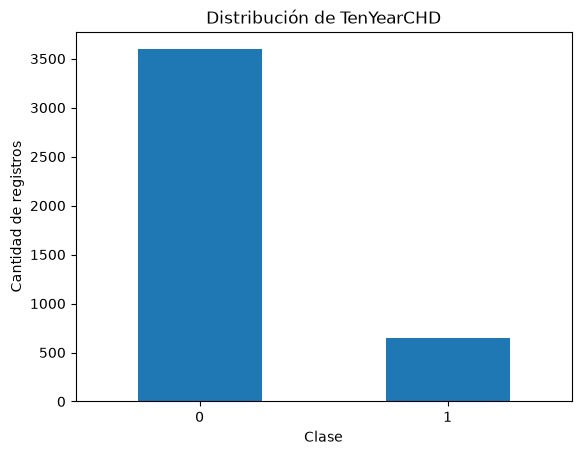

In [10]:
import matplotlib.pyplot as plt

df["TenYearCHD"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Distribución de TenYearCHD")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.show()

Por lo analizado ahora si se puede definir el problema.
<u>Problema:</u> predecir si una persona presenta riesgo de desarrollar enfermedad coronaria (CHD) durante los próximos diez años.
- 0: no desarrolló CHD durante ese período.
- 1: desarrolló CHD durante ese período.
La variable objetivo será TenYearCHD.

Pero según lo observado hay un desbalance de clases que debe ser considerado

<h2>Regresión</h2>

<h3>Preparación de variables</h3>

In [11]:
# Variables predictoras
X = df.drop(columns=["TenYearCHD"])

# Variable objetivo
y = df["TenYearCHD"]

Entrenanmiento 80%, prueba 20%

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y #mantiene aproximadamente la misma proporción de ceros y unos en ambos conjuntos
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución de entrenamiento:")
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribución de prueba:")
print(y_test.value_counts(normalize=True) * 100)

Entrenamiento: (3390, 15)
Prueba: (848, 15)

Distribución de entrenamiento:
TenYearCHD
0    84.80826
1    15.19174
Name: proportion, dtype: float64

Distribución de prueba:
TenYearCHD
0    84.787736
1    15.212264
Name: proportion, dtype: float64


No todas las columnas presentan el mismo tipo de dato, algunas columnas son categóricas, otras numericas continuas, otras binarias. Ademas de la correccion del desbalance mencionado anteriormente es necesario prestar atención a estas características. Por lo que separo las columnas para trabajar con ColumnTransformer

In [13]:
binary_cols = [
    "male",
    "currentSmoker",
    "BPMeds",
    "prevalentStroke",
    "prevalentHyp",
    "diabetes"
]

numeric_cols = [
    "age",
    "cigsPerDay",
    "totChol",
    "sysBP",
    "diaBP",
    "BMI",
    "heartRate",
    "glucose"
]

categorical_cols = ["education"]

In [17]:
binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))# se reemplaza con el valor más frecuente de esa columna.
])

In [14]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()) #estandarizado para comparar
])

In [15]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")) #convierto los niveles educativos en columnas binarias
])

El objeto preprocessor aplica la limpieza y transformaciones previas a cada grupo de columnas, esto lo hace mas legible y facil de definir

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("binary", binary_transformer, binary_cols),
        ("numeric", numeric_transformer, numeric_cols),
        ("categorical", categorical_transformer, categorical_cols)
    ]
)

In [22]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    #("classifier", LogisticRegression(max_iter=1000)) se cambia mas adelante ver explicacion
    ("classifier", LogisticRegression(
    max_iter=1000,  
    class_weight="balanced"
    ))
])

Entrenamiento y evaluación

In [23]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test) 
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}") #evaluacion preliminar, se usaran otras metricas

Accuracy: 0.6663


Como hay desbalance de clases no se puede usar solo la métrica Accuracy ya que aproximadamente el 84% de los registros pertenecen a la clase 0 (no desarrolló enfermedad). Es necesario mirar como se comporta en cada clase, en la siguiente seccion se evaluara el recall de la clase 1 porque nos permite observar cuántos casos positivos estamos dejando sin detectar

<u>Matriz de Confusión y métricas</u>

In [24]:
#Valores obtenidos inicialmente con ("classifier", LogisticRegression(max_iter=1000)) en la celda 19

cm = confusion_matrix(y_test, y_pred)

print("Matriz de confusión:")
print(cm)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Matriz de confusión:
[[489 230]
 [ 53  76]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.90      0.68      0.78       719
           1       0.25      0.59      0.35       129

    accuracy                           0.67       848
   macro avg       0.58      0.63      0.56       848
weighted avg       0.80      0.67      0.71       848



708: identificó correctamente personas de clase 0.

11: clasificó como positivas personas que eran de clase 0.

122: clasificó como negativas personas que eran de clase 1.

7: identificó correctamente personas de clase 1.


El dato más importante es el recall de la clase 1: 0.05 cuando no hay balanceo de clases
Esto significa que el modelo detectó aproximadamente el 5 % de los casos positivos debido al desbalance de clases, se cambia el classifier de la celda 19 para que aplique balanceo de clases y estos son los valores

Recall: pasó de 5 % a 59 %. Ahora detecta 76 de los 129 casos positivos.

Precision: bajó de 39 % a 25 %. De cada 100 predicciones positivas, aproximadamente 25 son correctas.

Accuracy: bajó de 84 % a 67 %.

<b>Cual es mejor</b>

Si el objetivo es detectar la mayor cantidad posible de casos positivos, el modelo balanceado parece más interesante. Pero no debemos ignorar su precision relativamente baja.>Ya que esto es un ejercicio de clasificación, no una herramienta para diagnosticar o estimar riesgos médicos reales, podriamos usar los datos que se obtuvieron con el balanceo de clases

In [ ]:
#modelo balanceado
y_proba = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)

print(f"ROC-AUC: {roc_auc:.4f}")

ROC-AUC: 0.6956


ROC-AUC mide la capacidad del modelo para distinguir entre las dos clases considerando distintos umbrales de clasificación.

Su valor está entre 0 y 1:
- 0.5: capacidad de discriminación equivalente al azar
- 1.0: discriminación perfecta
- 0.6956: el modelo tiene cierta capacidad para distinguir ambas clases, aunque todavía está lejos de una discriminación excelente
Por ejemplo, si elegimos al azar un caso positivo y uno negativo, el modelo tiene aproximadamente un 69,56 % de probabilidad de asignarle una puntuación mayor al caso positivo

In [28]:
#clonamos el modelo para compararlo con el que no esta balanceado

model_sin_balanceo = clone(model)

model_sin_balanceo.set_params(
    classifier__class_weight=None
)

model_sin_balanceo.fit(X_train, y_train)

y_proba_sin_balanceo = model_sin_balanceo.predict_proba(X_test)[:, 1]

roc_auc_sin_balanceo = roc_auc_score(
    y_test,
    y_proba_sin_balanceo
)

print(f"ROC-AUC sin balanceo: {roc_auc_sin_balanceo:.4f}")

ROC-AUC sin balanceo: 0.6953


Ya que ambos dan un valor de ROC-AUC similar, es preferible quedarse con el modelo que tiene clases balanceadas ya que el recall paso de 5% a 59%, y el F1 de 0.10 a 0.35

In [29]:
y_proba_balanceado = model.predict_proba(X_test)[:, 1]

In [31]:
for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_pred_threshold = (y_proba_balanceado >= threshold).astype(int)

    print(f"\nUmbral: {threshold}")
    print(classification_report(y_test, y_pred_threshold))


Umbral: 0.5
              precision    recall  f1-score   support

           0       0.90      0.68      0.78       719
           1       0.25      0.59      0.35       129

    accuracy                           0.67       848
   macro avg       0.58      0.63      0.56       848
weighted avg       0.80      0.67      0.71       848


Umbral: 0.4
              precision    recall  f1-score   support

           0       0.92      0.53      0.67       719
           1       0.22      0.74      0.34       129

    accuracy                           0.56       848
   macro avg       0.57      0.63      0.50       848
weighted avg       0.81      0.56      0.62       848


Umbral: 0.3
              precision    recall  f1-score   support

           0       0.96      0.34      0.51       719
           1       0.20      0.91      0.33       129

    accuracy                           0.43       848
   macro avg       0.58      0.63      0.42       848
weighted avg       0.84      0.43  

Se observa que bajar el umbral aumenta la cantidad de casos que clasificamos como positivos, pero también aumenta los falsos positivos. El umbral 0.3 parece ser el que mejores metricas tiene si se busca maximizar el recall. Voy a evaluarlos y visualizarlo mejor

In [33]:

resultados = []

for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_pred_threshold = (
        y_proba_balanceado >= threshold
    ).astype(int)

    resultados.append({
        "Umbral": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1-score": f1_score(y_test, y_pred_threshold)
    })

import pandas as pd

df_resultados = pd.DataFrame(resultados)

df_resultados.round(4)

,Umbral,Accuracy,Precision,Recall,F1-score
0,0.5,0.6663,0.2484,0.5891,0.3494
1,0.4,0.5590,0.2184,0.7364,0.3369
2,0.3,0.4316,0.2003,0.9147,0.3287
3,0.2,0.2771,0.1703,0.9690,0.2897


Bajar el umbral no hace que el modelo aprenda mejor sino que cambia el criterio que utilizamos para convertir una probabilidad en una clasificación.
El modelo balanceado con umbral 0.5 es candidato principal.

1. Tiene el mayor F1-score de todos los umbrales
2. Su recall es considerablemente mejor que el del modelo sin balanceo
3. Evita el incremento tan fuerte de falsos positivos que aparece con umbrales menores

<b>Observacion</b>
Los umbrales se probaron directamente sobre X_test con fines exploratorios, pero en realidad el conjunto de prueba no debería utilizarse para elegir el umbral definitivo

Lo siguiente es separar los datos en:
- Entrenamiento: para aprender los parámetros del modelo
- Validación: para comparar modelos y elegir el umbral
- Prueba: para evaluar una sola vez la configuración elegid
Para eso se cambiaran los porcentajes para entrenamiento, validacion y prueba


In [34]:
# Primero separamos el conjunto de prueba
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Después dividimos el 80 % restante en entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

In [35]:
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (2542, 15)
Validación: (848, 15)
Prueba: (848, 15)


In [36]:
print("Distribución entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución validación:")
print(y_val.value_counts(normalize=True))

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True))

Distribución entrenamiento:
TenYearCHD
0    0.848151
1    0.151849
Name: proportion, dtype: float64

Distribución validación:
TenYearCHD
0    0.847877
1    0.152123
Name: proportion, dtype: float64

Distribución prueba:
TenYearCHD
0    0.847877
1    0.152123
Name: proportion, dtype: float64


In [38]:
#entrenamiento
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['male','age','education',...,'BMI','heartRate','glucose']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binary', ...), ('numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, 

In [ ]:
#probabilidades
y_proba_val = model.predict_proba(X_val)[:, 1]

In [40]:
#nuevas metricas
resultados_val = []

for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_pred_val = (y_proba_val >= threshold).astype(int)

    resultados_val.append({
        "Umbral": threshold,
        "Accuracy": accuracy_score(y_val, y_pred_val),
        "Precision": precision_score(y_val, y_pred_val),
        "Recall": recall_score(y_val, y_pred_val),
        "F1-score": f1_score(y_val, y_pred_val)
    })

df_resultados_val = pd.DataFrame(resultados_val)

df_resultados_val.round(4)

,Umbral,Accuracy,Precision,Recall,F1-score
0,0.5,0.6627,0.2698,0.7132,0.3915
1,0.4,0.5507,0.2284,0.8217,0.3575
2,0.3,0.4340,0.2020,0.9225,0.3315
3,0.2,0.2960,0.1741,0.9690,0.2952


El umbral 0.5 tiene el F1-score más alto: 0.3915.

A medida que bajamos el umbral:
- Aumenta el recall
- Disminuye la precision
- Disminuye el F1-score
- Disminuye el accuracy
Esto confirma que, para estos cuatro umbrales, el 0.5 ofrece el mejor equilibrio entre precision y recall según F1

In [41]:
# Probabilidades sobre el conjunto de prueba
y_proba_test = model.predict_proba(X_test)[:, 1]

# Aplicamos el umbral elegido
y_pred_test = (y_proba_test >= 0.5).astype(int)

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_test))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_test))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_proba_test), 4)
)

Matriz de confusión:
[[482 237]
 [ 55  74]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.90      0.67      0.77       719
           1       0.24      0.57      0.34       129

    accuracy                           0.66       848
   macro avg       0.57      0.62      0.55       848
weighted avg       0.80      0.66      0.70       848

ROC-AUC: 0.6922


El modelo balanceado consigue detectar bastantes más casos positivos que la versión sin balanceo que había probado inicialmente

Pero tiene una precision baja y una cantidad considerable de falsos positivos. El ROC-AUC de 0.6922 también indica que su capacidad de diferenciación es moderada

Teniendo en cuenta que es de aplicación académica elijo el modelo con balanceo:
- Se seleccionó regresión logística con class_weight="balanced" para compensar el desbalance de clases
- Se compararon diferentes umbrales utilizando validación
- Se seleccionó el umbral 0.5 porque obtuvo el mayor F1-score entre los umbrales evaluados
- Finalmente, se evaluó la configuración seleccionada sobre el conjunto de prueba


In [42]:
model.named_steps["classifier"]

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [43]:
print(model.feature_names_in_)

['male' 'age' 'education' 'currentSmoker' 'cigsPerDay' 'BPMeds'
 'prevalentStroke' 'prevalentHyp' 'diabetes' 'totChol' 'sysBP' 'diaBP'
 'BMI' 'heartRate' 'glucose']


<h3>Guardado del modelo</h3>
